# 1 · Waveforms; Time and frequency domain representations

**Question:** How does a gravitaional wave signal from a compact binary coalescence look like?

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.signal import stft
from scipy.signal.windows import tukey
from pycbc.frame import read_frame
from pycbc.filter import highpass, resample_to_delta_t
from pycbc.waveform import get_td_waveform, get_fd_waveform


/home/abhishek.sharma/miniconda3/envs/gw-env/lib/python3.11/site-packages/pycbc/types/array.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal as _lal
PyCBC.libutils: pkg-config call failed, setting NO_PKGCONFIG=1


In [2]:
GPS = 1126259462.4  # GW150914 geocentric GPS time
SAMPLING_FREQ = 2048  # analysis sampling frequency (Hz)
DURATION = 64
DATA_DIR = Path('../data')

def load_detector(ifo='H1'):

    """Read locally cached, unfiltered GWOSC strain and prepare it for analysis."""
    
    path = DATA_DIR / f'GW150914_{ifo}_4096Hz_64s.gwf'
    channel = f'{ifo}:GWOSC-4KHZ_R1_STRAIN'
    
    if not path.exists():
        raise FileNotFoundError(f'{path} not found. From the repository root run: python download_data.py')
    
    raw = read_frame(str(path), channel)
    highpassed = resample_to_delta_t(highpass(raw, 15.0), 1.0 / SAMPLING_FREQ)
    conditioned = highpassed.crop(2, 2)
    
    return conditioned

plt.rcParams.update({'figure.figsize':(11,4),'font.size':11})

## How does a compact-binary signal look?
During inspiral the orbit shrinks and the frequency and amplitude rise. At leading order,
$$\dot f = \frac{96}{5}\pi^{8/3}\left(\frac{G\mathcal M}{c^3}\right)^{5/3}f^{11/3},\qquad
\mathcal M=\frac{(m_1m_2)^{3/5}}{(m_1+m_2)^{1/5}}.$$
At a *fixed observed GW frequency*, larger chirp mass means faster frequency evolution and less remaining inspiral time.

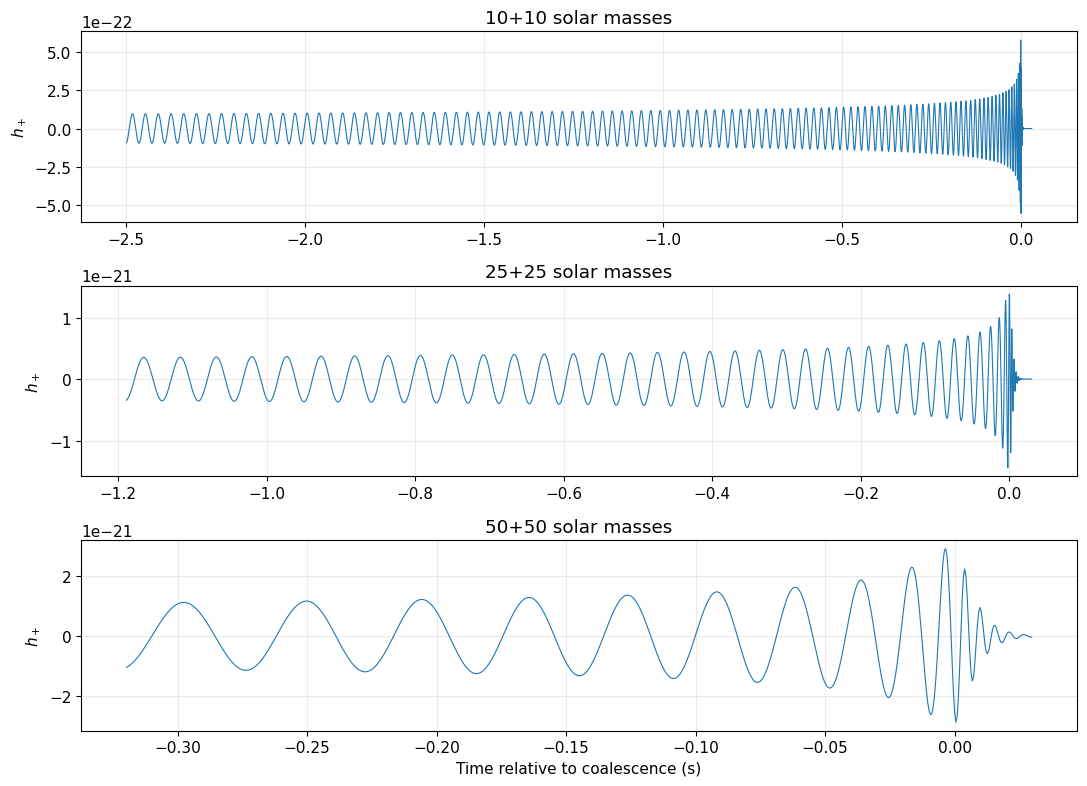

In [3]:
dt = 1/SAMPLING_FREQ
flow = 20
distance = 400 #Mpc

fig,axs=plt.subplots(3,1,figsize=(11,8))

for ax,(m1,m2) in zip(axs,[(10,10),(25,25),(50,50)]):
    hp,hc=get_td_waveform(approximant='SEOBNRv4',mass1=m1,mass2=m2,   # SEOBNRv4: Time-domain waveform model.
                          delta_t=dt,f_lower=flow,distance=distance)
    
    sel=(hp.sample_times>-2.5) & (hp.sample_times<0.03)
    ax.plot(hp.sample_times[sel],hp[sel],lw=.8)
    ax.set(ylabel=r'$h_+$',title=f'{m1}+{m2} solar masses')
    ax.grid(alpha=.25)

axs[-1].set_xlabel('Time relative to coalescence (s)')
plt.tight_layout();plt.show()

## Measure the chirp duration
Use the leading-order approximation for the time to coalescence at frequency $f$:
$$t_c-t\approx \frac{5}{256}(\pi f)^{-8/3}\left(\frac{G\mathcal M}{c^3}\right)^{-5/3}.$$
*This is an inspiral approximation, not a merger model.*

In [4]:
from scipy.constants import G,c,pi

MSUN=1.988409870698051e30

def chirp_mass(m1,m2):
    return (m1*m2)**(3/5)/(m1+m2)**(1/5)

def time_remaining(m1,m2,f=30):
    mc=chirp_mass(m1,m2)*MSUN
    return 5/256*(pi*f)**(-8/3)*(G*mc/c**3)**(-5/3)

for masses in [(10,10),(25,25),(50,50)]:
    print(masses,'chirp mass = %.1f Msun; t(30 Hz) = %.2f s'%(chirp_mass(*masses),time_remaining(*masses)))
    

(10, 10) chirp mass = 8.7 Msun; t(30 Hz) = 2.02 s
(25, 25) chirp mass = 21.8 Msun; t(30 Hz) = 0.44 s
(50, 50) chirp mass = 43.5 Msun; t(30 Hz) = 0.14 s


## Fourier transform: from time to frequency domain

The Fourier transform of the signal shows its **frequency content**. We use the convention

$$\tilde x(f)=\int x(t)e^{-2\pi ift}\,dt.$$

For a uniformly sampled series, NumPy's `rfft` calculates the positive-frequency part of the discrete Fourier transform. Multiplying by the sampling interval `dt` makes its normalization closer to the integral above. The frequency-bin separation is $\Delta f=1/T$, where $T$ is the observation duration.

**Prediction:** What frequencies should appear if our signal is the sum of two pure sine waves?

In [5]:
# A controlled signal with two known frequencies
dt = 1/SAMPLING_FREQ
T = 2.                      # seconds
t = np.arange(0, T, 1/SAMPLING_FREQ)
f1, f2 = 30, 90             # Hz
x = np.sin(2*np.pi*f1*t) + 0.6*np.sin(2*np.pi*f2*t)

frequency = np.fft.rfftfreq(len(x), d=1/SAMPLING_FREQ)
amplitude = np.abs(np.fft.rfft(x)) / SAMPLING_FREQ


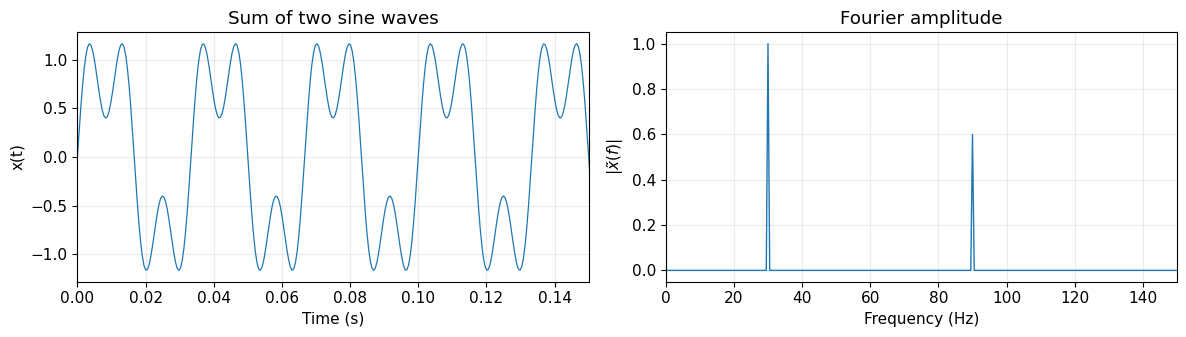

Frequency resolution = 0.5 Hz


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(t, x, lw=0.9)
axes[0].set(xlim=(0, 0.15), xlabel='Time (s)', ylabel='x(t)',
            title='Sum of two sine waves')
axes[1].plot(frequency, amplitude, lw=1)
axes[1].set(xlim=(0, 150), xlabel='Frequency (Hz)',
            ylabel=r'$|\tilde{x}(f)|$', title='Fourier amplitude')
for ax in axes: ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print('Frequency resolution =', 1/T, 'Hz')

## Fourier transform of a gravitational wave signal

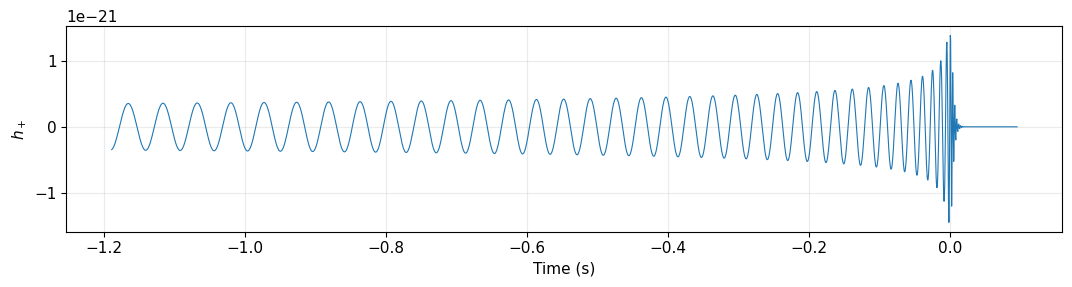

In [7]:
m1 = 25
m2 = 25
flow = 20
distance = 400

hp,hc=get_td_waveform(approximant='SEOBNRv4',
                      mass1=m1, mass2=m2,
                      delta_t=dt,
                      f_lower=flow,
                      distance=distance)

fig = plt.figure(figsize=(11,3))
plt.plot(hp.sample_times,hp,lw=.8)
# plt.plot(hc.sample_times,hc,lw=.8)
plt.ylabel(r'$h_+$')
plt.grid(alpha=.25)

plt.xlabel('Time (s)')
plt.tight_layout();plt.show()

Let us plot a waveform using Frequency domain approximant `IMRPhenomD` with the same parameters.

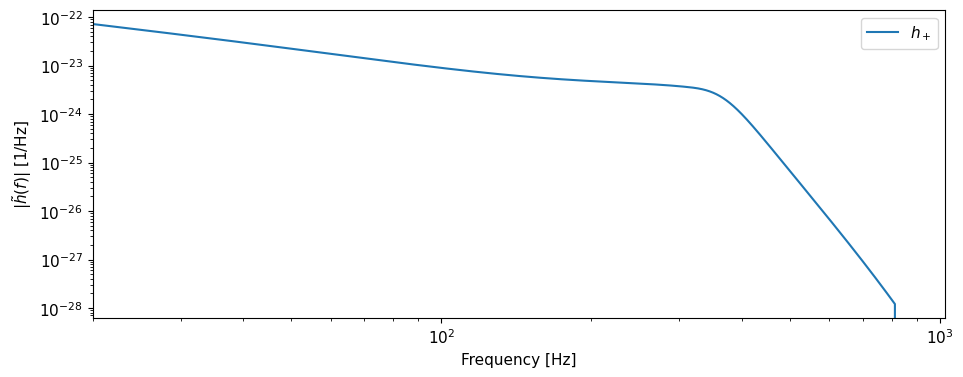

In [8]:
hpf, hcf = get_fd_waveform(
    approximant='IMRPhenomD',
    mass1=m1,
    mass2=m2,
    distance=distance,
    delta_f=0.125,
    f_lower=flow,
    f_ref=800.
)

plt.loglog(hpf.sample_frequencies, np.abs(hpf), label=r'$h_+$')
plt.xlabel('Frequency [Hz]')
plt.ylabel(r'$|\tilde{h}(f)|$ [1/Hz]')
plt.xlim([flow, SAMPLING_FREQ/2])
plt.legend()
plt.show()

Let us now compute the Fourier transform of the time-domain waveform:

Text(0.5, 1.0, 'Direct FFT of time-domain waveform')

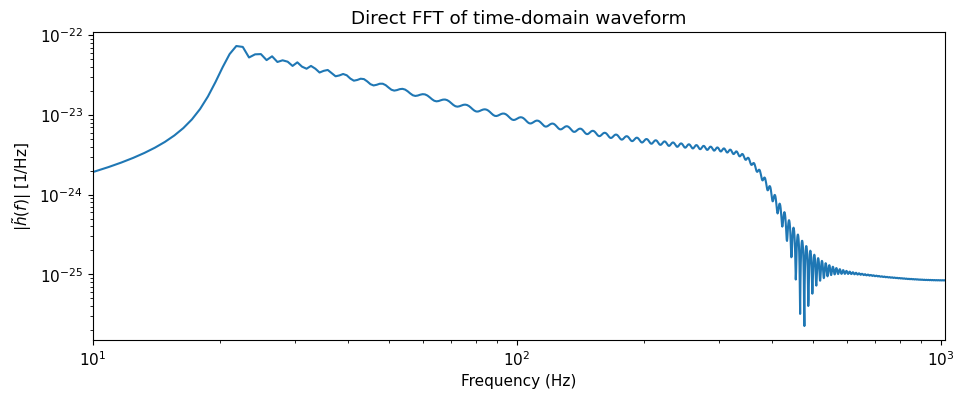

In [9]:
# -- Apply the real Fast Fourier Transform (rfft)
dt = hp.delta_t
hp_fft = dt * np.fft.rfft(hp)
freq_fft = np.fft.rfftfreq(len(hp), d=dt)

##  This can also be done using `to_frequencyseries()` method of PyCBC Timeseries.
# hpf = hp.to_frequencyseries()
# plt.loglog(hpf.sample_frequencies, np.abs(hpf))

plt.loglog(freq_fft, np.abs(hp_fft))
plt.xlim(flow/2, SAMPLING_FREQ/2)
plt.xlabel('Frequency (Hz)')
plt.ylabel(r'$|\tilde{h}(f)|$ [1/Hz]')
plt.title("Direct FFT of time-domain waveform")

### A finite observation causes spectral leakage

An FFT treats the measured segment as one period of a repeating signal. If the first and last values do not join smoothly, this artificial discontinuity spreads power across many frequency bins. 

**Spectral leakage** is the general effect; ripples associated with a sharp truncation are often called *Gibbs-like oscillations*. Strictly speaking, the *Gibbs phenomenon* refers to overshoot near a discontinuity in a Fourier-series reconstruction.

A **Tukey window** reduces these edge discontinuities by tapering the data to zero near its boundaries. This suppresses sidelobes but also changes the signal (and broadens spectral peaks): windowing is a trade-off, not a way to recover lost information.

2629
5258


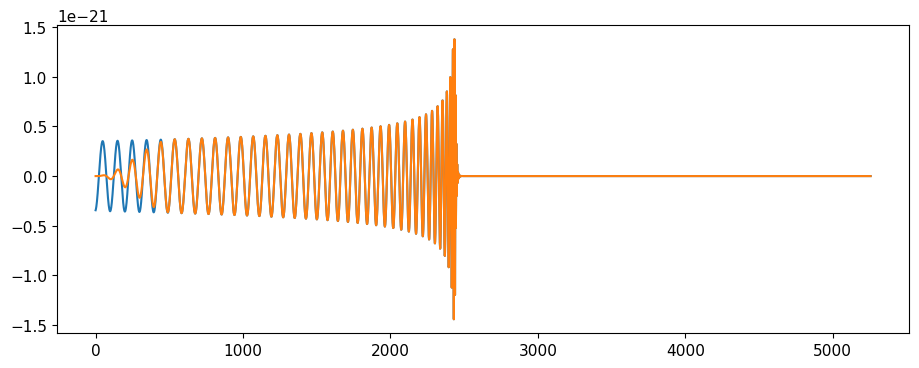

In [10]:
# The window forces the signal to zeros at the beginning and end.
# This must be done before applying a Fourier Transform
# The parameter alpha is the fraction of the time interval to be tapered; for convenience, we also zero-pad the waveform.
print(len(hp))
hp_pad = np.concatenate((hp, np.zeros(len(hp), dtype=float)))
print(len(hp_pad))
window = tukey(len(hp_pad), alpha=0.2)

plt.plot(hp_pad)
plt.plot(window*hp_pad)

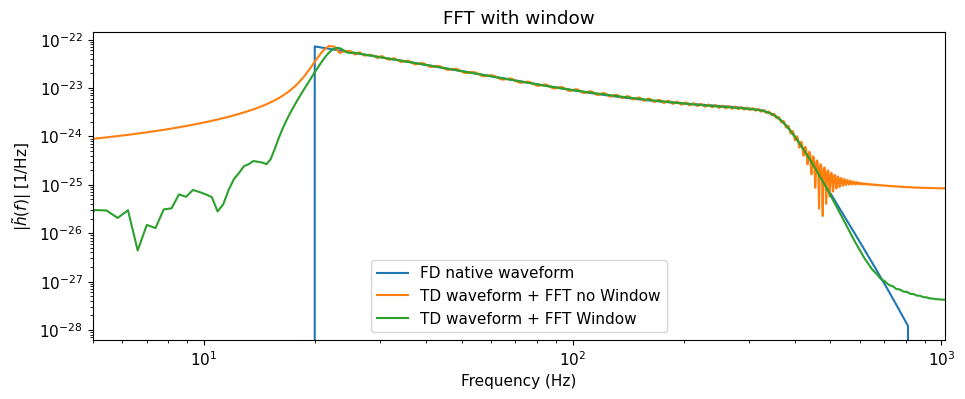

In [11]:
# Apply the real Fast Fourier Transform (rfft)
dt = hp.delta_t
hp_w_fft = dt * np.fft.rfft((window*hp_pad))
freq_w_fft = np.fft.rfftfreq(len(hp_pad), d=dt)

plt.loglog(hpf.sample_frequencies, np.abs(hpf), label='FD native waveform')
plt.loglog(freq_fft, np.abs(hp_fft), label='TD waveform + FFT no Window')
plt.loglog(freq_w_fft, np.abs(hp_w_fft), label='TD waveform + FFT Window')
plt.xlim(5., SAMPLING_FREQ/2)
plt.xlabel('Frequency (Hz)')
plt.ylabel(r'$|\tilde{h}(f)|$ [1/Hz]')
plt.title("FFT with window")
plt.legend()

## Time-frequency analysis

Fourier transform highlights the frequency content of the full time-domain signal. Gravitational wave signals are transient.

How do we study the evolution of signal's frequency content with time? This is achieved by **short-term Fourier transform (STFT)**.

**STFT** divides the signal into overlapping windows and Fourier-transforms each one. A **spectrogram** displays the resulting time-dependent frequency content.

A shorter analysis window gives better time localization but poorer frequency resolution, and vice versa.

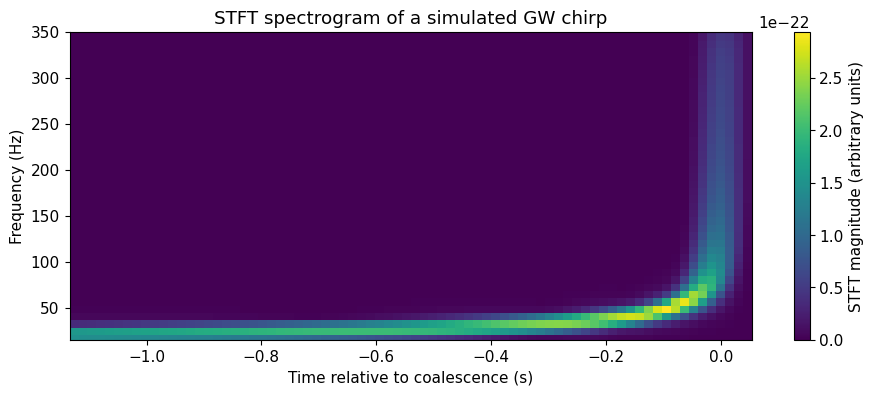

In [12]:
# Time-frequency map for the *simulated* inspiral segment.
frequencies_stft, times_stft, Z = stft(
    hp, fs=SAMPLING_FREQ, window='hann',
    nperseg=256, noverlap=224, boundary=None) # nperseg: length of each segment, noverlap: number of points to overlap between segments.
                                              # large nperseg -> better freq resolution, lower time resolution
                                              # small nperseg -> lower freq resolution, better time resolution
fig, ax = plt.subplots(figsize=(11, 4))
mesh = ax.pcolormesh(hp.sample_times[0] + times_stft, frequencies_stft,
                     np.abs(Z), shading='auto')
ax.set(xlabel='Time relative to coalescence (s)', ylabel='Frequency (Hz)',
       ylim=(15, 350), title='STFT spectrogram of a simulated GW chirp')
fig.colorbar(mesh, ax=ax, label='STFT magnitude (arbitrary units)')
plt.show()

### Exercise:

1. Change the second frequency in the two-sine example from 90 Hz to 32 Hz. Can you resolve both peaks? What changes if the recording lasts only 0.5 s?
2. In the STFT plot, try `nperseg=128` and `512`. Describe the time-frequency trade-off.

## Q-Transform

SFTF with a window width depending on frequency (inversely proportional to the frequency).


The Q-transform shown here uses GWpy.

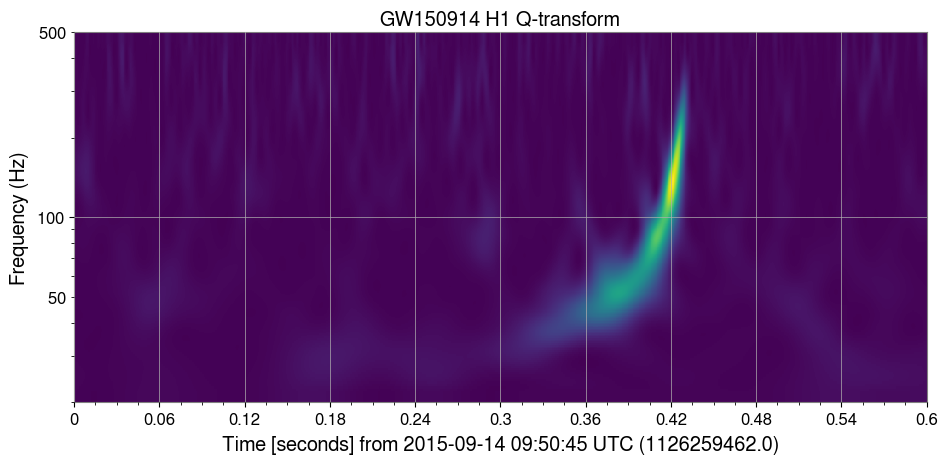

In [13]:
from gwpy.timeseries import TimeSeries as GWTimeSeries

# Use GW150914 data.
h1=load_detector('H1')
gw=GWTimeSeries(np.asarray(h1),sample_rate=SAMPLING_FREQ,t0=float(h1.start_time))

q=gw.q_transform(outseg=(GPS-.4,GPS+.2),frange=(20,500),qrange=(4,64))

fig=q.plot(figsize=(11,5))
ax=fig.gca()
ax.set_yscale('log')
ax.set_ylim(20,500)
ax.set_title('GW150914 H1 Q-transform')
ax.set_ylabel('Frequency (Hz)')
plt.show()

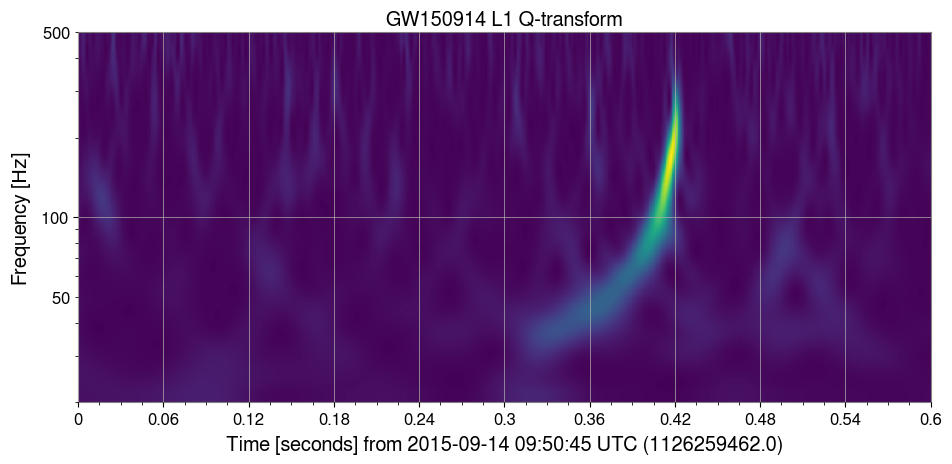

In [14]:
l1=load_detector('L1')

gw_l1=GWTimeSeries(np.asarray(l1),sample_rate=SAMPLING_FREQ,t0=float(l1.start_time))
q_l1=gw_l1.q_transform(outseg=(GPS-.4,GPS+.2),frange=(20,500),qrange=(4,64))

fig=q_l1.plot(figsize=(11,5))
ax=fig.gca()
ax.set_yscale('log')
ax.set_ylim(20,500)
ax.set_title('GW150914 L1 Q-transform')
plt.show()

### Exercise
1. Change $(m_1,m_2)$ to $(30,10)M_\odot$. Compare the duration and amplitude with an equal-mass binary.
2. Change Q-transform frequency limits to 30–300 Hz: does the chirp look different?
3. Does a bright time-frequency feature alone establish an astrophysical origin? **No:** glitches can be bright too.
